# Entrega 2 — Modelos de cumplimiento crediticio | Grupo 19
**ELCO 2022 · Modelos A (crédito) y B (crédito + hogar)**

Objetivo: comparar la capacidad de identificar créditos con retrasos para apoyar la priorización **orientativa** de revisión por parte de un analista. Prototipo académico; no se utiliza para aprobar o rechazar créditos.

## 1. Configuración y lectura

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score, f1_score,
                             PrecisionRecallDisplay)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
ROOT = Path.cwd()
CANDIDATOS = [ROOT/'ELCO_2022_creditos_ahorro_laboral_consolidado.csv',
              ROOT/'data'/'ELCO_2022_creditos_ahorro_laboral_consolidado.csv',
              ROOT/'files'/'ELCO_2022_creditos_ahorro_laboral_consolidado.csv',
              ROOT/'entrega_elco'/'ELCO_2022_creditos_ahorro_laboral_consolidado.csv']
RUTA = next((p for p in CANDIDATOS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError('Coloque el CSV consolidado junto al notebook o en data/.')
OUT = ROOT/'resultados_entrega2'; OUT.mkdir(exist_ok=True)
df = pd.read_csv(RUTA)
assert len(df) == 4013 and df['DIRECTORIO'].nunique() == 3020, 'Revisar versión de datos.'
assert df['objetivo_atraso'].isin([0,1]).all()
assert (df['objetivo_atraso'] == (df['P2110']==2).astype(int)).all()
print('Base:', df.shape, '| Hogares:',df.DIRECTORIO.nunique(), '| Atrasos:', df.objetivo_atraso.sum())

Base: (4013, 34) | Hogares: 3020 | Atrasos: 675


## 2. Variables y control de filtraciones

In [2]:
CATEGORICAS = ['P2097','P2098','P2106']
NUMERICAS_A = ['P2099S2','P2104','P2105S1','P2107S1']
HOGAR = ['n_personas_ahorro','n_personas_con_ingresos','n_personas_que_ahorran',
         'prop_que_ahorran_sobre_con_ingresos','n_personas_con_cuenta',
         'n_personas_laboral','n_personas_trabajo_semana']
VARIABLES_A = CATEGORICAS + NUMERICAS_A
VARIABLES_B = VARIABLES_A + HOGAR
base = df.copy()
# El código 9999 se considera ausencia de respuesta, no 9999 meses.
base.loc[base['P2107S1']==9999,'P2107S1'] = np.nan
# P2110 es la respuesta de la encuesta que define el objetivo: nunca entra como predictor.
# Se excluyen identificadores, P2108 (saldo actual), y otras variables de posible información posterior.
assert not set(['P2110','P2108','DIRECTORIO']).intersection(VARIABLES_B)
print('Variables A:', VARIABLES_A)
print('Variables adicionales B:', HOGAR)
print('Faltantes relevantes:\n',base[VARIABLES_B].isna().sum().loc[lambda s:s>0].to_string())

Variables A: ['P2097', 'P2098', 'P2106', 'P2099S2', 'P2104', 'P2105S1', 'P2107S1']
Variables adicionales B: ['n_personas_ahorro', 'n_personas_con_ingresos', 'n_personas_que_ahorran', 'prop_que_ahorran_sobre_con_ingresos', 'n_personas_con_cuenta', 'n_personas_laboral', 'n_personas_trabajo_semana']
Faltantes relevantes:
 P2105S1                                135
P2107S1                                128
prop_que_ahorran_sobre_con_ingresos    163


## 3. División independiente por hogar (70 % / 15 % / 15 % aproximadamente)

In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED)
ix_train, ix_temp = next(gss.split(base, base['objetivo_atraso'], groups=base['DIRECTORIO']))
train = base.iloc[ix_train].copy(); temporal = base.iloc[ix_temp].copy()
gss2 = GroupShuffleSplit(n_splits=1, test_size=.50, random_state=SEED+1)
ix_val,ix_test = next(gss2.split(temporal, temporal['objetivo_atraso'],groups=temporal['DIRECTORIO']))
val = temporal.iloc[ix_val].copy(); test = temporal.iloc[ix_test].copy()
for x,y in [(train,val),(train,test),(val,test)]:
    assert set(x.DIRECTORIO).isdisjoint(set(y.DIRECTORIO))
for nom,parte in [('Entrenamiento',train),('Validación',val),('Prueba',test)]:
    print(nom, len(parte),'créditos,',parte.DIRECTORIO.nunique(),'hogares, atraso:',round(parte.objetivo_atraso.mean(),3))
    assert set(parte.objetivo_atraso)=={0,1}, f'{nom}: faltó una clase' 

Entrenamiento 2808 créditos, 2114 hogares, atraso: 0.173
Validación 613 créditos, 453 hogares, atraso: 0.153
Prueba 592 créditos, 453 hogares, atraso: 0.16


## 4. Cuatro experimentos comparables

In [4]:
def crear_pipeline(vars_, algoritmo):
    cats = [c for c in CATEGORICAS if c in vars_]
    nums = [c for c in vars_ if c not in cats]
    pre = ColumnTransformer([
        ('num',Pipeline([('imputar',SimpleImputer(strategy='median',add_indicator=True)),
                         ('escalar',StandardScaler())]),nums),
        ('cat',Pipeline([('imputar',SimpleImputer(strategy='most_frequent')),
                         ('ohe',OneHotEncoder(handle_unknown='ignore'))]),cats)
    ])
    if algoritmo=='Logistica':
        model=LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED)
    else:
        model=RandomForestClassifier(n_estimators=200,min_samples_leaf=5,
                                     class_weight='balanced_subsample',random_state=SEED,n_jobs=-1)
    return Pipeline([('preparacion',pre),('modelo',model)])

experimentos = {'A_logistica':(VARIABLES_A,'Logistica'), 'A_bosque':(VARIABLES_A,'Bosque'),
                'B_logistica':(VARIABLES_B,'Logistica'), 'B_bosque':(VARIABLES_B,'Bosque')}
modelos={}; registros=[]; probas_test={}
y_train=train.objetivo_atraso; y_val=val.objetivo_atraso; y_test=test.objetivo_atraso
umbrales = np.round(np.arange(.10,.91,.05),2)
for nombre,(vars_,algo) in experimentos.items():
    pipe=crear_pipeline(vars_,algo)
    pipe.fit(train[vars_],y_train)
    pv=pipe.predict_proba(val[vars_])[:,1]
    # Selección de umbral exclusivamente en validación, sin consultar prueba.
    puntajes=[f1_score(y_val,(pv>=u).astype(int),zero_division=0) for u in umbrales]
    umbral=float(umbrales[int(np.argmax(puntajes))])
    pt=pipe.predict_proba(test[vars_])[:,1]
    pred=(pt>=umbral).astype(int)
    modelos[nombre]=pipe; probas_test[nombre]=pt
    registros.append({'experimento':nombre,'variables': 'A: crédito' if nombre.startswith('A') else 'B: crédito + hogar',
       'algoritmo':algo,'umbral_validacion':umbral,
       'precision_atraso':precision_score(y_test,pred,zero_division=0),
       'recall_atraso':recall_score(y_test,pred,zero_division=0),
       'f1_atraso':f1_score(y_test,pred,zero_division=0),
       'pr_auc':average_precision_score(y_test,pt)})
resultados=pd.DataFrame(registros).set_index('experimento')
print(resultados.round(3).to_string())
resultados.to_csv(OUT/'comparacion_modelos.csv')

                      variables  algoritmo  umbral_validacion  precision_atraso  recall_atraso  f1_atraso  pr_auc
experimento                                                                                                      
A_logistica          A: crédito  Logistica               0.50             0.291          0.611      0.395   0.375
A_bosque             A: crédito     Bosque               0.55             0.406          0.453      0.428   0.428
B_logistica  B: crédito + hogar  Logistica               0.50             0.296          0.621      0.401   0.382
B_bosque     B: crédito + hogar     Bosque               0.50             0.364          0.453      0.404   0.431


## 5. Comparación y decisión de éxito

Alternativas elegidas usando validación: A_bosque y B_bosque
Δ recall B-A en prueba: 0.0 | Δ precision B-A: -0.041
Meta académica propuesta alcanzada: No


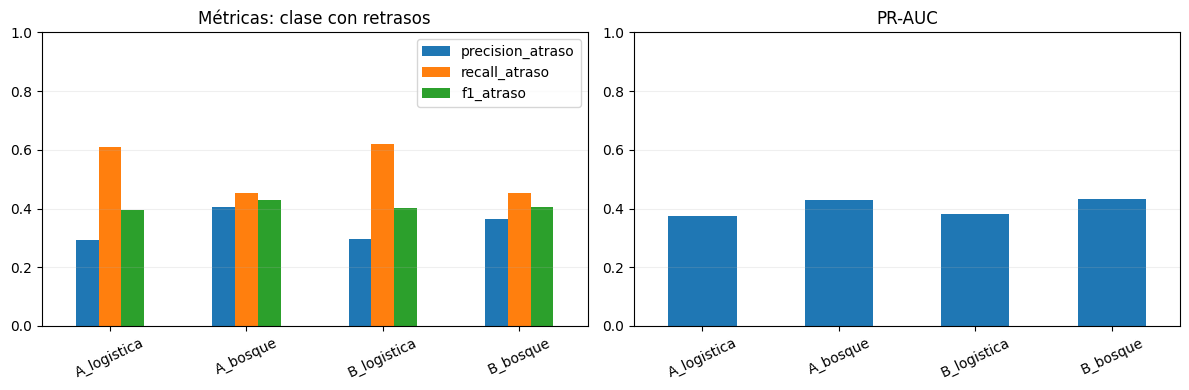

In [5]:
# Se elige cada alternativa según PR-AUC de validación, sin consultar los resultados de prueba.
pr_validacion={nombre:average_precision_score(y_val,modelos[nombre].predict_proba(val[experimentos[nombre][0]])[:,1]) for nombre in modelos}
nombre_A=max((k for k in modelos if k.startswith('A')),key=lambda k:pr_validacion[k])
nombre_B=max((k for k in modelos if k.startswith('B')),key=lambda k:pr_validacion[k])
mejor_A=resultados.loc[nombre_A]; mejor_B=resultados.loc[nombre_B]
delta_recall=float(mejor_B.recall_atraso-mejor_A.recall_atraso)
delta_precision=float(mejor_B.precision_atraso-mejor_A.precision_atraso)
meta=(delta_recall>=.05) and (delta_precision>=-.03)
print('Alternativas elegidas usando validación:',nombre_A,'y',nombre_B)
print('Δ recall B-A en prueba:',round(delta_recall,3),'| Δ precision B-A:',round(delta_precision,3))
print('Meta académica propuesta alcanzada:', 'Sí' if meta else 'No')
fig,axs=plt.subplots(1,2,figsize=(12,4))
resultados[['precision_atraso','recall_atraso','f1_atraso']].plot(kind='bar',ax=axs[0],ylim=(0,1),rot=25,title='Métricas: clase con retrasos')
resultados['pr_auc'].plot(kind='bar',ax=axs[1],ylim=(0,1),rot=25,title='PR-AUC')
for a in axs:a.grid(axis='y',alpha=.2);a.set_xlabel('')
plt.tight_layout(); plt.savefig(OUT/'metricas_modelos.png',dpi=170);plt.show()

## 6. Matrices de confusión y curvas precisión–recall

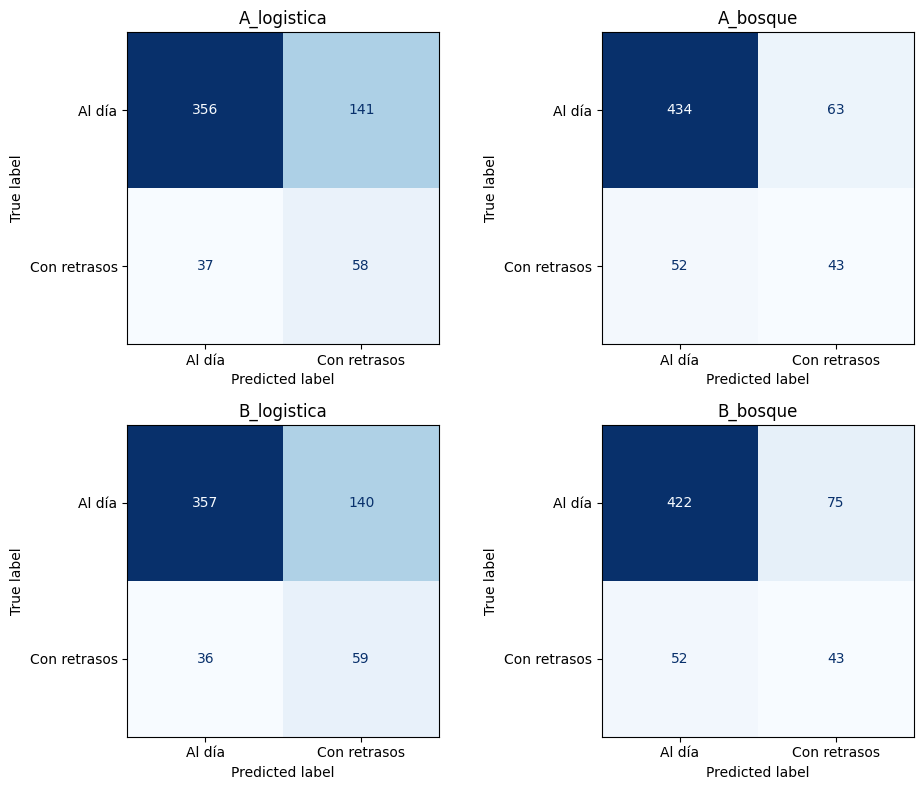

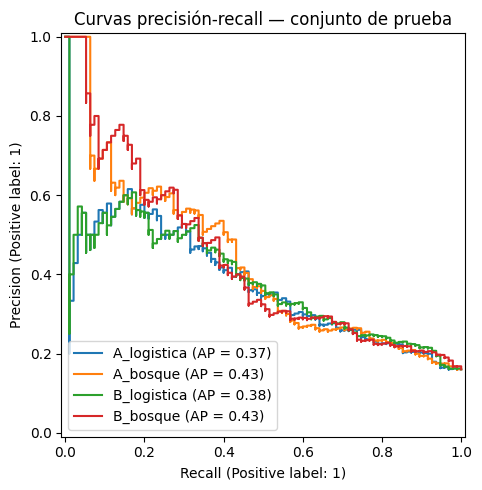

In [6]:
fig,axes=plt.subplots(2,2,figsize=(10,8))
for ax,(nombre,probas) in zip(axes.ravel(),probas_test.items()):
    umbral=resultados.loc[nombre,'umbral_validacion']
    matriz=confusion_matrix(y_test,(probas>=umbral).astype(int),labels=[0,1])
    ConfusionMatrixDisplay(matriz,display_labels=['Al día','Con retrasos']).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(nombre)
plt.tight_layout();plt.savefig(OUT/'matrices_confusion.png',dpi=170);plt.show()
fig,ax=plt.subplots(figsize=(8,5))
for nombre,probas in probas_test.items():
    PrecisionRecallDisplay.from_predictions(y_test,probas,name=nombre,ax=ax)
ax.set_title('Curvas precisión-recall — conjunto de prueba');plt.tight_layout()
plt.savefig(OUT/'curvas_precision_recall.png',dpi=170);plt.show()

## 7. Sensibilidad del año de inicio del crédito

In [7]:
# Comprobar si la variable temporal influye sustancialmente en la comparación, sin afirmar causalidad.
for grupo,vars_ in [('A',VARIABLES_A),('B',VARIABLES_B)]:
    sin_anio=[x for x in vars_ if x!='P2099S2']
    pipe=crear_pipeline(sin_anio,'Logistica');pipe.fit(train[sin_anio],y_train)
    pv=pipe.predict_proba(val[sin_anio])[:,1]
    pts=[f1_score(y_val,pv>=u,zero_division=0) for u in umbrales]
    u=float(umbrales[int(np.argmax(pts))])
    pt=pipe.predict_proba(test[sin_anio])[:,1]
    print(grupo,'sin año | PR-AUC:',round(average_precision_score(y_test,pt),3),
          '| recall:',round(recall_score(y_test,pt>=u,zero_division=0),3))
print('Esta sensibilidad no elimina el sesgo de supervivencia propio de los créditos observados en 2022.')

A sin año | PR-AUC: 0.282 | recall: 0.642
B sin año | PR-AUC: 0.291 | recall: 0.547
Esta sensibilidad no elimina el sesgo de supervivencia propio de los créditos observados en 2022.


## 8. Entrega de modelos y contrato de integración

In [8]:
# Para despliegue se recomienda decidir el modelo usando validación; se registran las métricas de test por separado.
# Selección por PR-AUC de validación, sin utilizar las métricas del conjunto de prueba.
pr_val={nombre:average_precision_score(y_val,modelos[nombre].predict_proba(val[experimentos[nombre][0]])[:,1]) for nombre in modelos}
elegido=max(pr_val,key=pr_val.get)
modelo_final=modelos[elegido]; vars_final=experimentos[elegido][0]
umbral_final=float(resultados.loc[elegido,'umbral_validacion'])
joblib.dump(modelo_final,OUT/'modelo_seleccionado.joblib')
contrato={'modelo':elegido,'variables_en_orden':vars_final,'categoricas':[c for c in CATEGORICAS if c in vars_final],
          'numericas':[c for c in vars_final if c not in CATEGORICAS],
          'umbral':umbral_final,'clase_positiva':1,
          'interpretacion':'Probabilidad de clase con retrasos; prototipo académico, no aprobación crediticia',
          'origen':'ELCO 2022 DANE; entrenamiento con separación por hogar'}
(OUT/'contrato_modelo.json').write_text(json.dumps(contrato,indent=2,ensure_ascii=False),encoding='utf-8')
# Ejemplo de solicitud sin información identificadora.
ejemplo={k:(int(test.iloc[0][k]) if k in CATEGORICAS and pd.notna(test.iloc[0][k]) else
            float(test.iloc[0][k]) if pd.notna(test.iloc[0][k]) else None) for k in vars_final}
(OUT/'ejemplo_entrada.json').write_text(json.dumps(ejemplo,indent=2,ensure_ascii=False),encoding='utf-8')
print('Modelo elegido por PR-AUC de validación:',elegido)
print('Umbral:',umbral_final)
print('Archivos generados:',[p.name for p in OUT.iterdir()])

Modelo elegido por PR-AUC de validación: A_bosque
Umbral: 0.55
Archivos generados: ['ejemplo_entrada.json', 'comparacion_modelos.csv', 'contrato_modelo.json', 'curvas_precision_recall.png', 'metricas_modelos.png', 'matrices_confusion.png', 'modelo_seleccionado.joblib']


## 9. Resultados y limitaciones
Los resultados numéricos anteriores proceden exclusivamente de la base ELCO 2022. El desempeño corresponde a créditos históricos presentes en la encuesta, no demuestra causalidad ni garantiza desempeño futuro. Los indicadores del hogar y el estado de pago se observan en el mismo corte, por lo que debe verificarse su disponibilidad temporal antes de cualquier uso operativo.

**Para integración:** Nicolás puede registrar cada corrida en MLflow y desplegar `modelo_seleccionado.joblib` junto con `contrato_modelo.json`; Raúl puede implementar el formulario de entrada siguiendo `variables_en_orden` y visualizar la probabilidad, la clasificación y la advertencia de uso académico. **AWS EC2, MLflow y API no se implementan en este notebook.**